# AI-aided pair

**Research question:** How does TiRex2's forecasting behavior change depending on the characteristics of the input time series and the forecasting configuration, and what types of inputs lead to different failure modes?

## Setup

In [1]:
from data_loading import load_all, multi_value_datasets, best_worst_configs
import plotss as P
import diagnostics as d
import embedding as E
import importlib

df_windows, df_series, df_config = load_all()

df_forecasts = d.build_forecast_table("output/results/TiRex2", cache_path="forecasts.parquet")
df_analysis  = d.merge_with_windows(df_windows, df_forecasts)

windows with forecast diagnostics: 100.0% of 109607


## Where does the model work and fail?

### 1. Overview across configurations and datasets

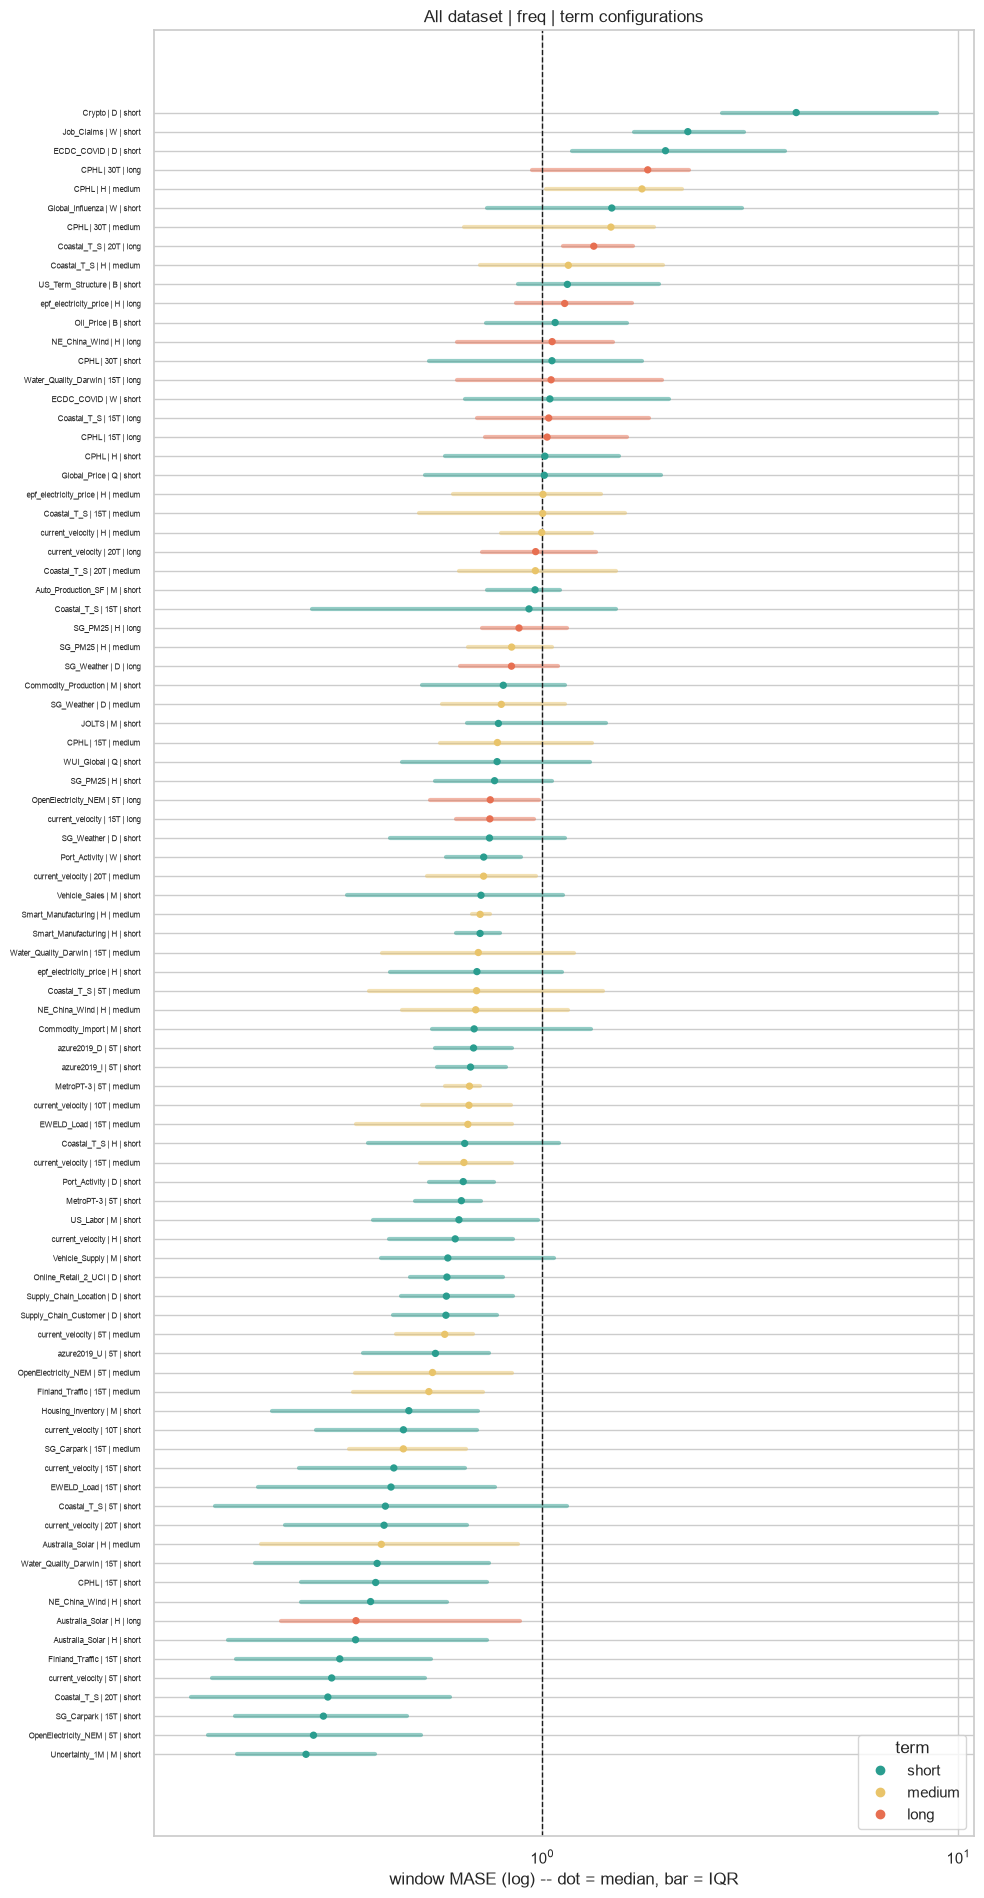

In [2]:
P.plot_config_overview(df_config)

The bar is MASE = 1 and is meant to be a simple naive benchmark that shows how well the model predicts different datasets. For datasets such as Crypto|D|short and Job_Claims|W|short the model performs worse than the baseline. But on the other side, the models is outperforming the baseline for, mostly, short term dataset configurations. Overall, the plot demonstates that the model is struggling more with the long and medium term.

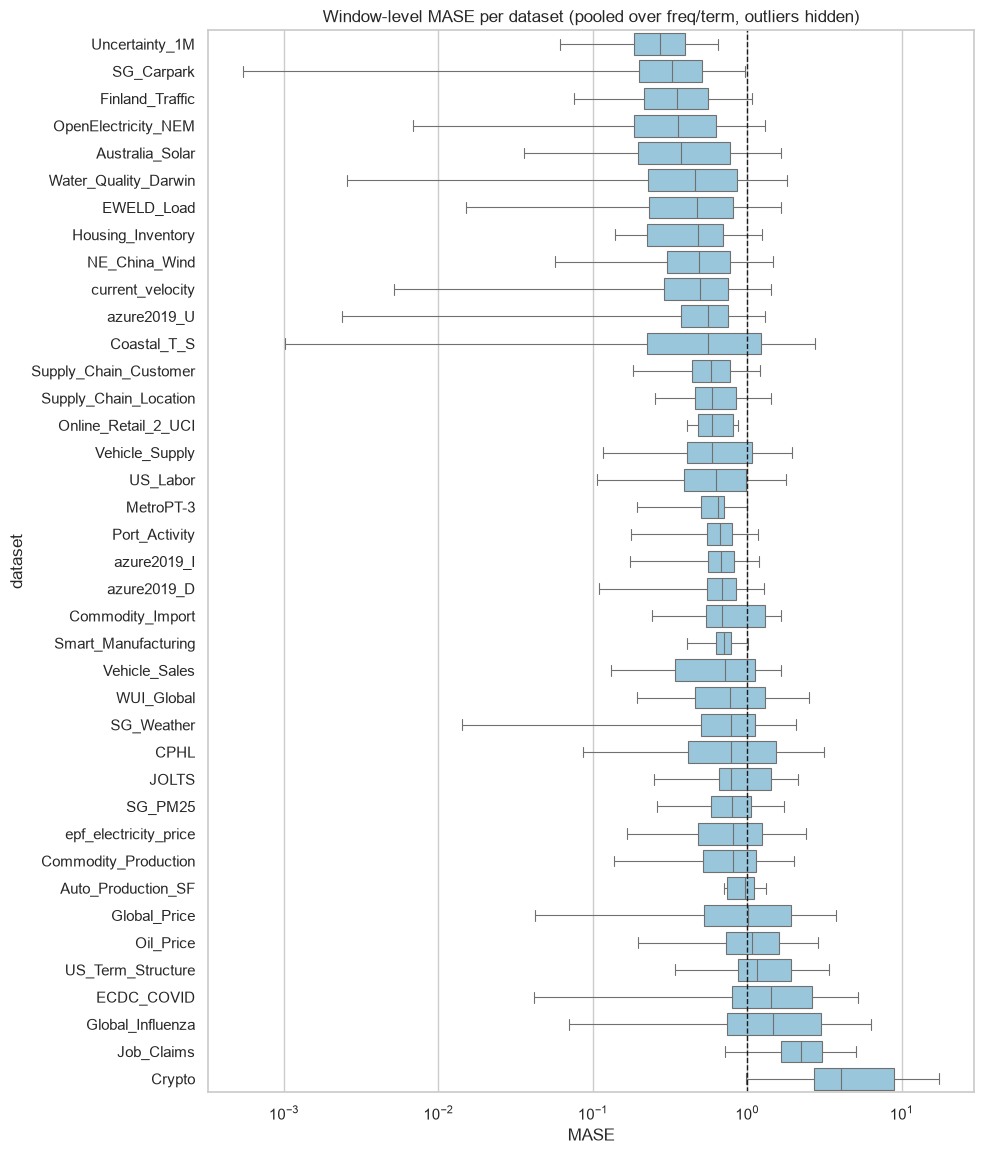

In [3]:
P.plot_mase_by_dataset(df_windows)

High-noise financial datasets stay near the bottom with meadians of near 1.0 or above, proving they are hard to predict across all frequencies and terms. Sensor, physical and traffic datasets set near the top, showing strong predictability across setups. Datasets such as SG_carparl and Coastal_T_S with wide boxes and long whiskers show that performance depends heavily on the specific term or frequency chosen. 

<!-- In the figures above, the model underperforms for Job_Claims, Global_Influenza, ECDC_Covid -->

### 2. Effect of forecast term

In [85]:
multi_value_datasets(df_config, "term")

['Australia_Solar',
 'CPHL',
 'Coastal_T_S',
 'EWELD_Load',
 'Finland_Traffic',
 'MetroPT-3',
 'NE_China_Wind',
 'OpenElectricity_NEM',
 'SG_Carpark',
 'SG_PM25',
 'SG_Weather',
 'Smart_Manufacturing',
 'Water_Quality_Darwin',
 'current_velocity',
 'epf_electricity_price']

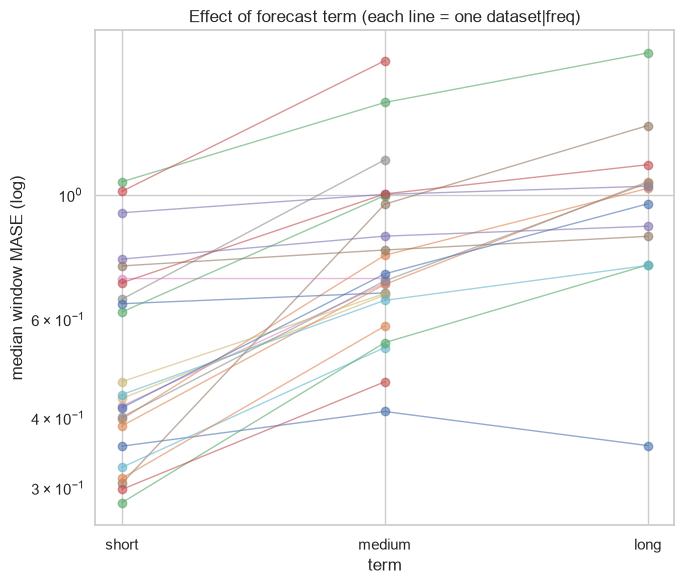

In [96]:
P.plot_term_comparison(df_config)

Evaluating model performance across forecast terms reveals consistent horizon degradation across nearly all dataset configurations. While TiRex2 demonstrates strong baseline superiority in short-term, performance systematically decays toward or past the naive baseline  as the horizon extends to medium and long terms. 

### 3. Effect of sampling frequency

In [84]:
multi_value_datasets(df_config, "freq")

['CPHL', 'Coastal_T_S', 'ECDC_COVID', 'Port_Activity', 'current_velocity']

20% of multi-frequency datasets have MASE increasing monotonically with coarser sampling


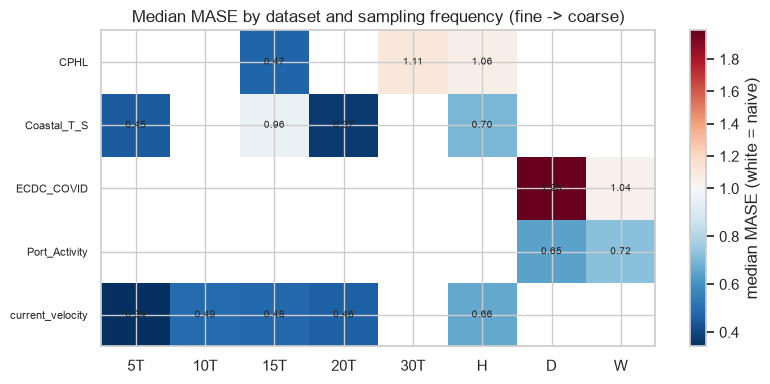

In [88]:
P.plot_freq_heatmap(df_analysis)

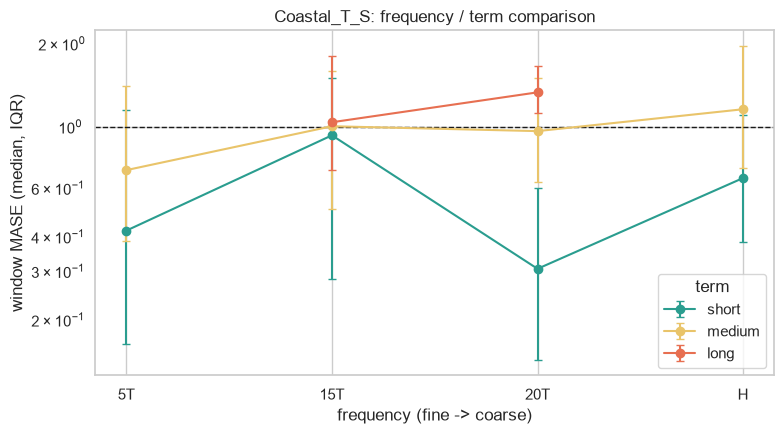

In [8]:
P.plot_freq_comparison(df_config, "Coastal_T_S")

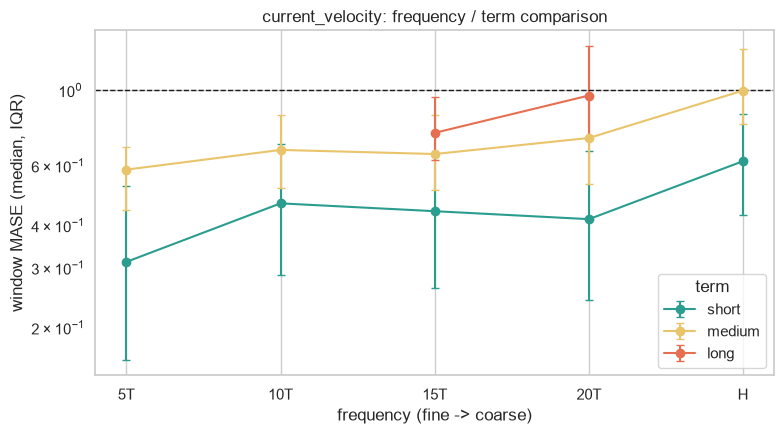

In [9]:
P.plot_freq_comparison(df_config, "current_velocity")

Comparing frequency sensitivity between Coastal_T_S and current_velocity highlights two distinct behavioral modes in the data. While Coastal_T_S exhibits non-monotonic aliasing effects, current_velocity demonstrates monotonic error growth as sampling frequency coarsens. For current_velocity, fine 5-minute sampling (5T) yields the best accuracy ($\text{MASE} \approx 0.30$), while hourly aggregation (H) degrades medium-term predictions to the naive baseline threshold ($\text{MASE} = 1.0$). Across all multi-frequency datasets, strictly monotonic error growth with coarser sampling is surprisingly rare, occuring only 20% of the configurations. Making current_velocity an exception

### Best vs Worst configurations

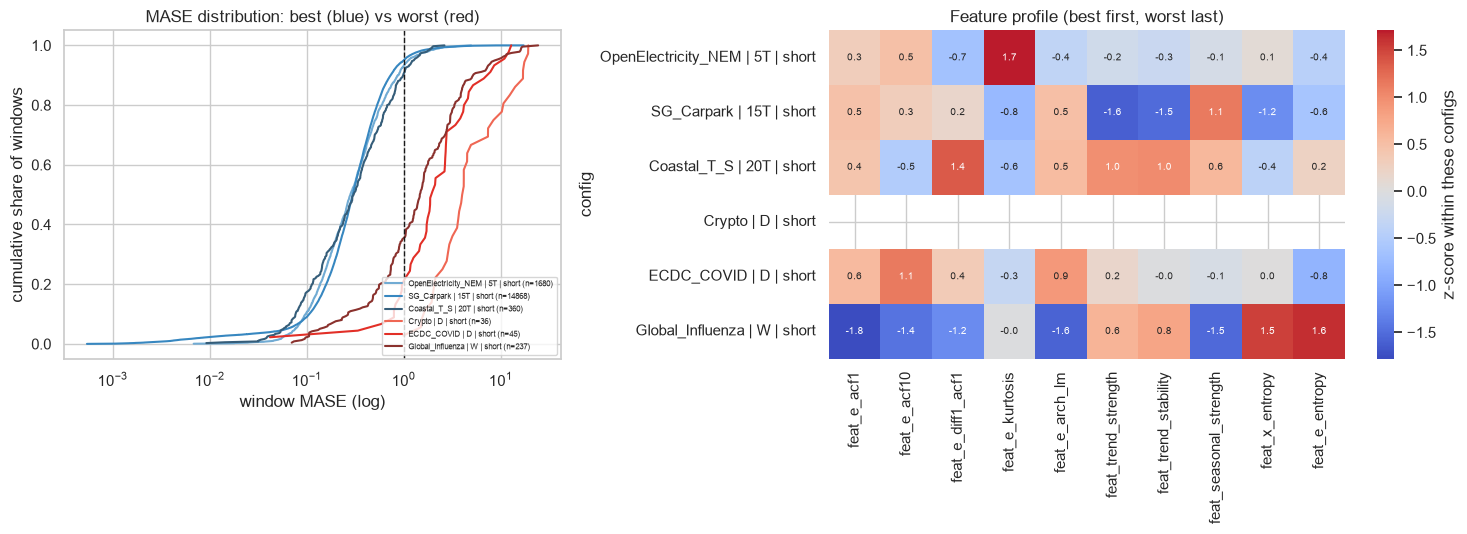

In [10]:
best, worst = best_worst_configs(df_config, k=3, min_windows=30)
P.plot_best_worst(df_windows, best, worst)

In this plot, the top 3 best and worst performing dataset setups are compared. In the left plot, the blue curves (best), sits mostly to the left, achieving $\text{MASE}<1.0$. The red curves (worst) sit mostly to the right of 1.0. For Crypto|D|short, $100\%$ of windows exceed the naive baseline. There is also a difference in the steepness of the slopes: the blue curves are steep, meaning the model's performance is highly consistent across windows, whereas the red curves have wider, shallower slopes, indicating high variance between windows (some windows might do good, while others have massive error spikes).

Z-score feature profile reveals why the model might fail for some dataset configurations. The model might rely on trend strength in combination with seasonal strength to outperform the baseline. In addition, entropy could also be an important factor in the performance of the model. By taking into account the different combinations of these factors, we can see why the curves behave the way they do.

## Why?

### 1. Feature profile of configurations

No features available, left out of the profile: ['Crypto']


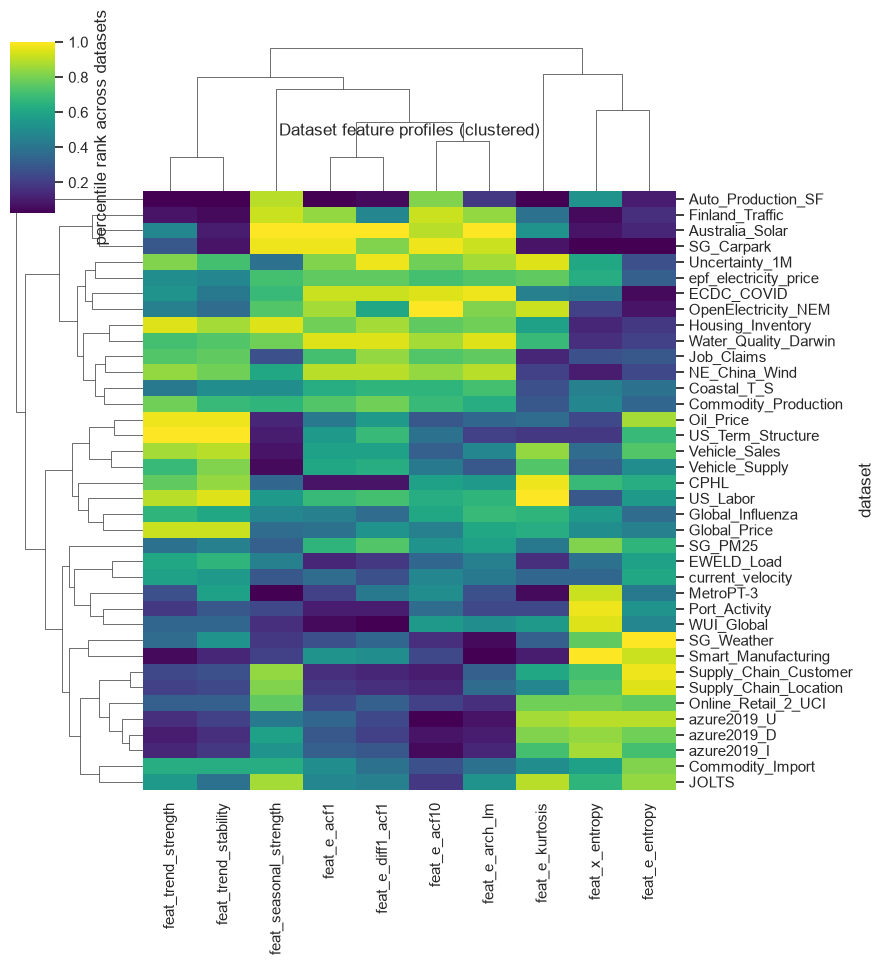

In [4]:
P.plot_feature_profile(df_config)

Underperforming configuration differ from the best ones in their feature profile, such as lower seasonal strenght and higher entropy. Although these are just a few features and it might not be the sole reason the model behaves like this.

### 2. Feature-error relationship

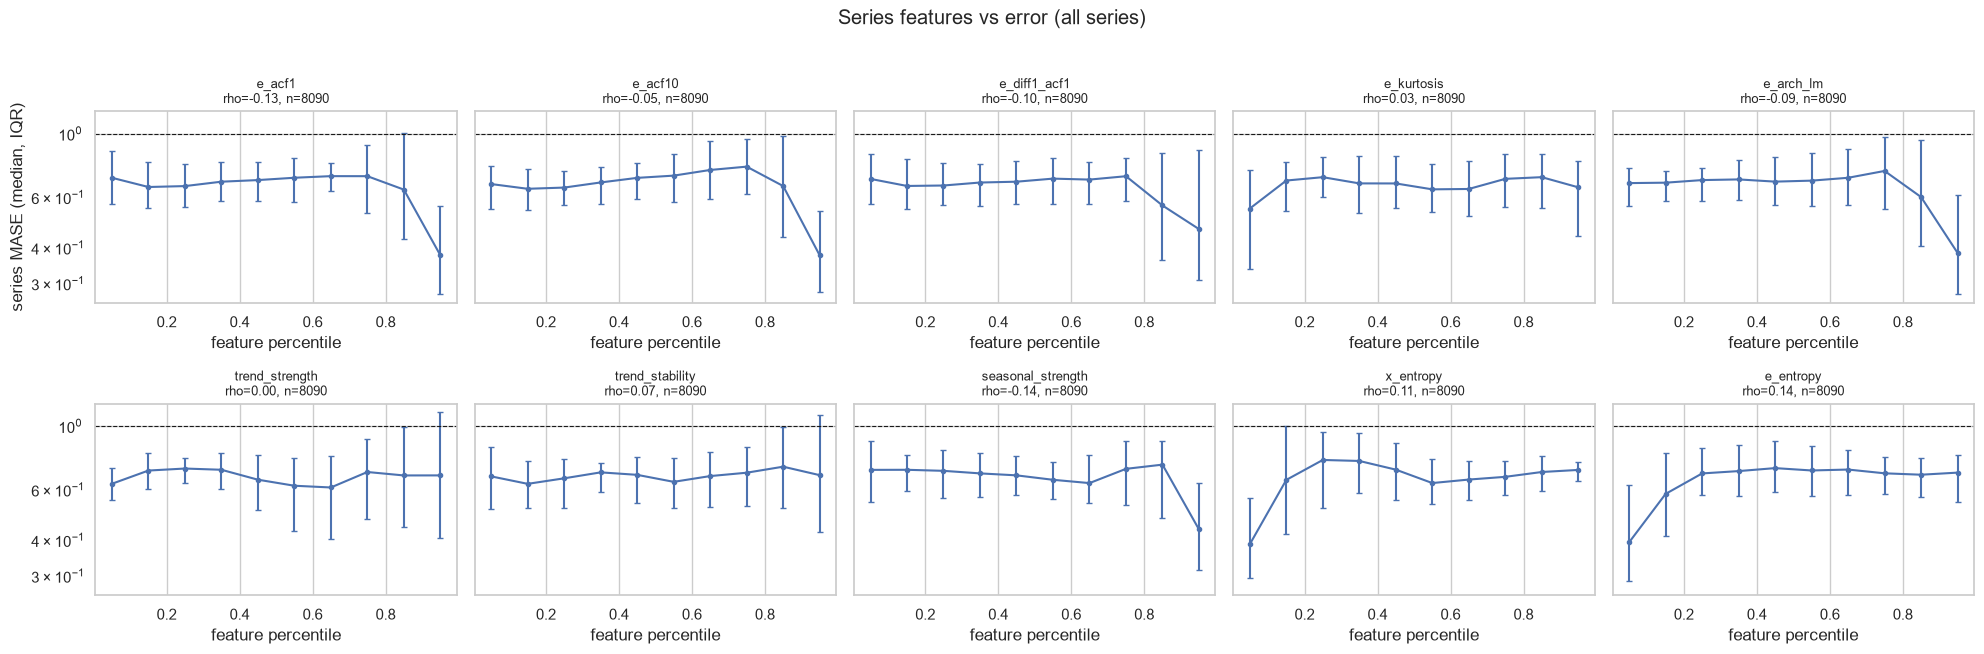

In [98]:
P.plot_feature_error_relationship(df_series)

Evaluating feature-error relationships across all 8,090 individual series confirms that model performance is governed by non-linear feature thresholds rather than smooth linear trends. High lag-1 autocorrelation (e_acf1, $\rho = -0.13$) and strong seasonal periodicity (seasonal_strength, $\rho = -0.14$) serve as primary prerequisites for high precision, driving median error down from $\text{MASE} \approx 0.70$ to $\sim 0.38–0.45$ in the top 20th feature percentiles. Conversely, structural entropy (e_entropy, $\rho = +0.14$) presents a strict performance wall: series exceeding the 20th entropy percentile suffer immediate error elevation. Notably, pure linear trend strength (trend_strength, $\rho = 0.00$) exhibits zero correlation with forecast accuracy, reinforcing the model's reliance on periodic structure over linear momentum.

## Point-forecast behaviours

### 1. Seasonal amplitude damping and flat-lining

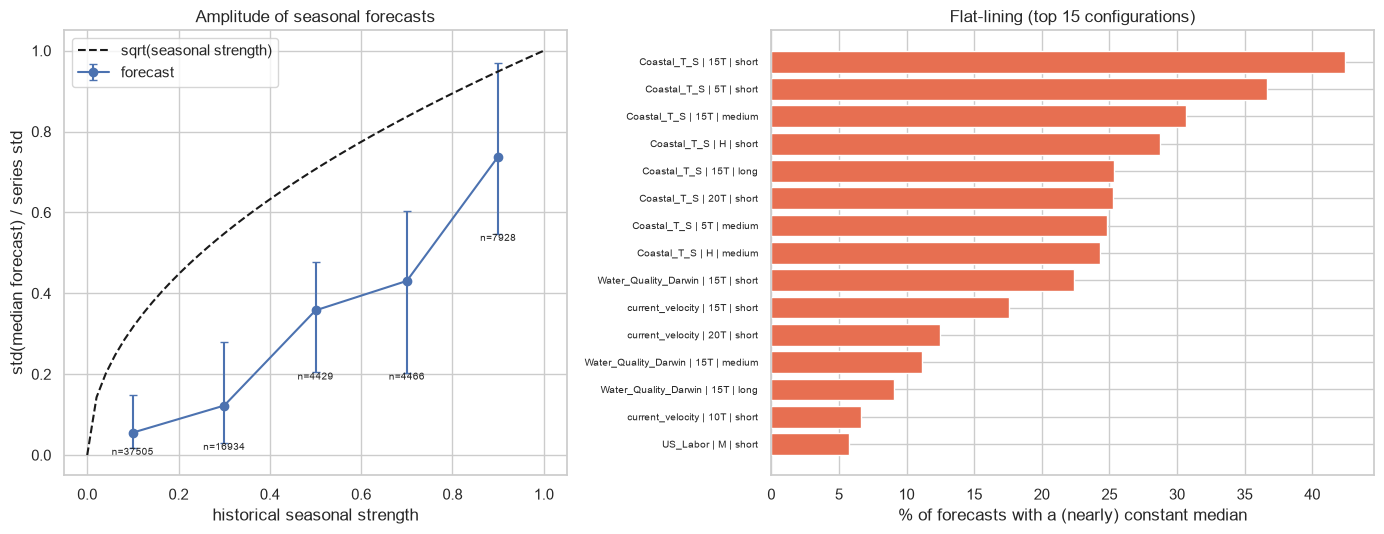

In [99]:
P.plot_seasonal_damping(df_analysis)

On the left: The Theoretical Reference(black dashed line) represents the expected amplitude if the model fully reproduced the historical seasonal component. The blue curve sit consistently below the reference line across all bins. For weak to moderate seasonality(0.0-0.4) TiRex2 dampens the variance, forecast amplitude dropping near 0. For strong seasonality (0.8-1.0), TiRex2 can recover only ~$75\%$ of the expected std, even though the historical seasonality is extremely high. This could mean that TiRex2 has a built-in variance suppression bias. It systematically smooths out seasonal peaks and troughts to minimize square errors rather than outputting full-amplitute cycles.

On the right: Flat-lining is the percentage of evaluation windows where the median trajectory degenerates into a nearly constant horizontal line. Majority of Coastal_T_S configurations have a high precentage of flat median forecasts. 9 out of 15 configurations are short terms, which might indicate that when TiRex2 is dealing with high short-term noise or very fine sampling resolutions,the default safety mechanism is to output a constant level(flat line) rather than risk dynamic predictions. 

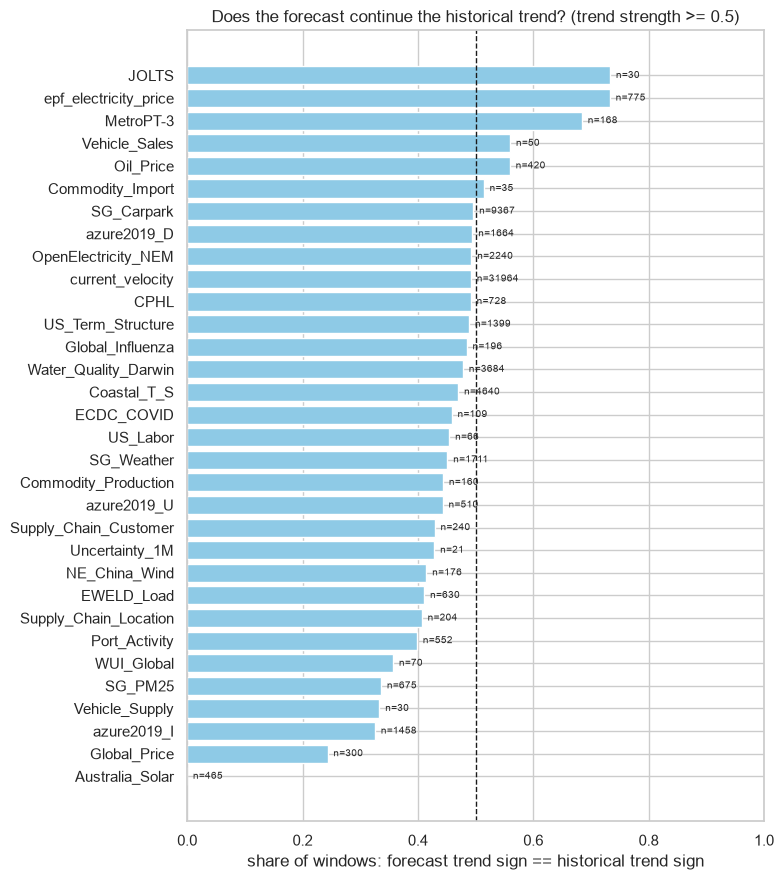

In [101]:
P.plot_drift_vs_history_trend(df_analysis)

Based on this plot, TiRex2 has a dominant mean-reversive prior, it predicts the opposite of the past trend. Most of the datasets are to the left and Australia_Solar is close to 0. It would be interesting to see why the model does this in Phase II. 

## Uncertainty

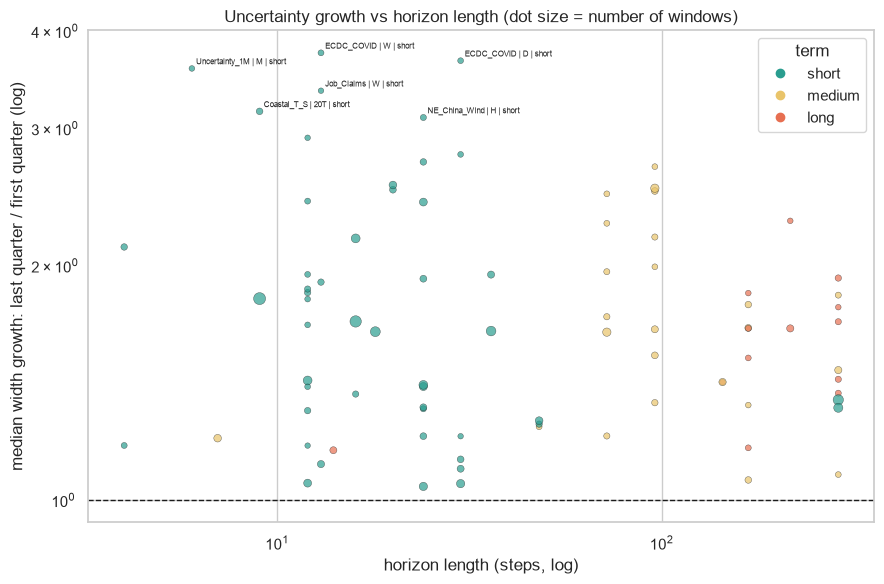

In [11]:
P.plot_width_growth_overview(df_analysis)

An overview of uncertainty growth across all configurations confirms universal interval expansion ($\text{width growth} > 1.0$), demonstrating that TiRex2 reliably scales prediction bounds as temporal horizons extend. The sharpest relative growth ratios ($3.0\times–4.0\times$) occur in short-horizon, high-volatility configurations (ECDC_COVID, Job_Claims), where initial confidence is high but rapidly decays. Conversely, long-horizon configurations exhibit more conservative, steady growth ratios ($1.2\times–2.0\times$) due to wider baseline initial intervals.

A key finding in uncertainty evaluation is the contrast between baseline error and relative uncertainty growth. While Uncertainty_1M achieves the lowest overall median MASE in the benchmark ($\text{MASE} < 0.3$), it exhibits a high relative uncertainty growth ratio ($\sim 3.6\times$). This paradox is driven by a tiny initial denominator: because initial step confidence is exceptionally high (narrow intervals), standard horizon variance accumulation produces a large percentage increase while absolute error remains minimal.

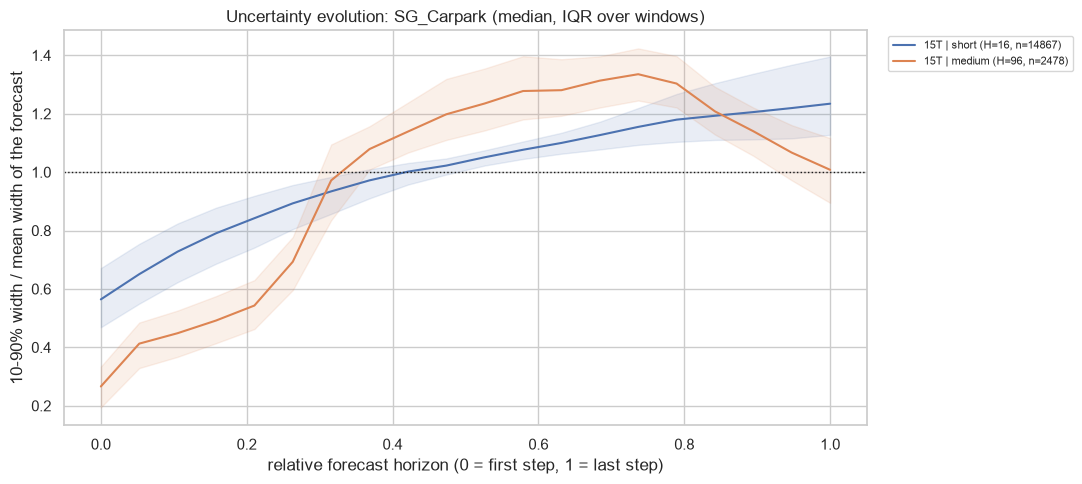

In [12]:
P.plot_uncertainty_evolution(df_analysis, "SG_Carpark")

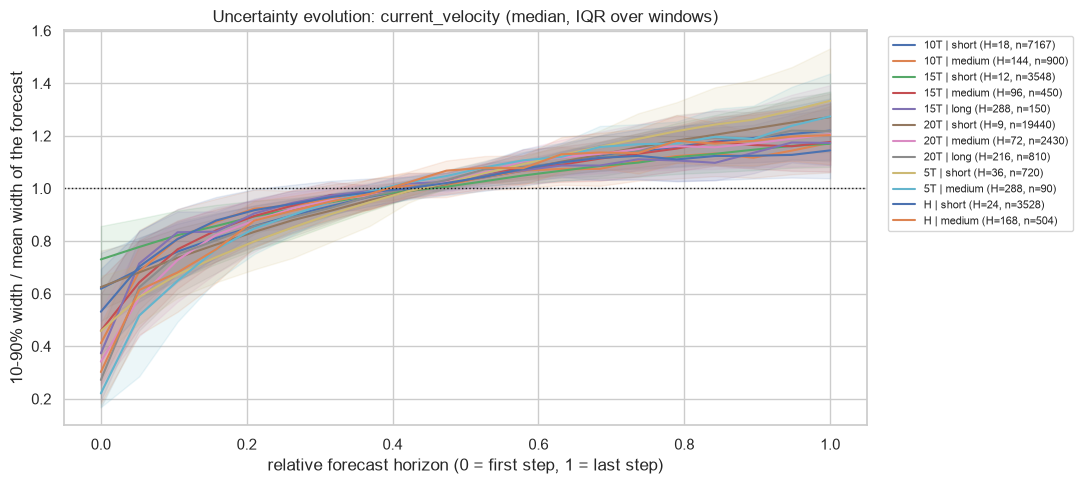

In [13]:
P.plot_uncertainty_evolution(df_analysis, "current_velocity")

To understand the mechanisms behind the macro uncertainty trends, we examine two contrasting case studies:  current_velocity: Across all frequencies and terms, relative interval width grows continuously with the horizon.  SG_Carpark: In the medium term ($15T, H=96$), uncertainty expands mid-horizon but contracts back to ~1.0 at step 1.0. Because $96 \times 15\text{ min} = 24\text{ hours}$, TiRex2 might leverage learned daily occupancy cycles to reduce uncertainty at complete periodic boundaries, something that is  missing in shorter, non-periodic horizons ($H=16$). This might be something interesting to see in Phase II.

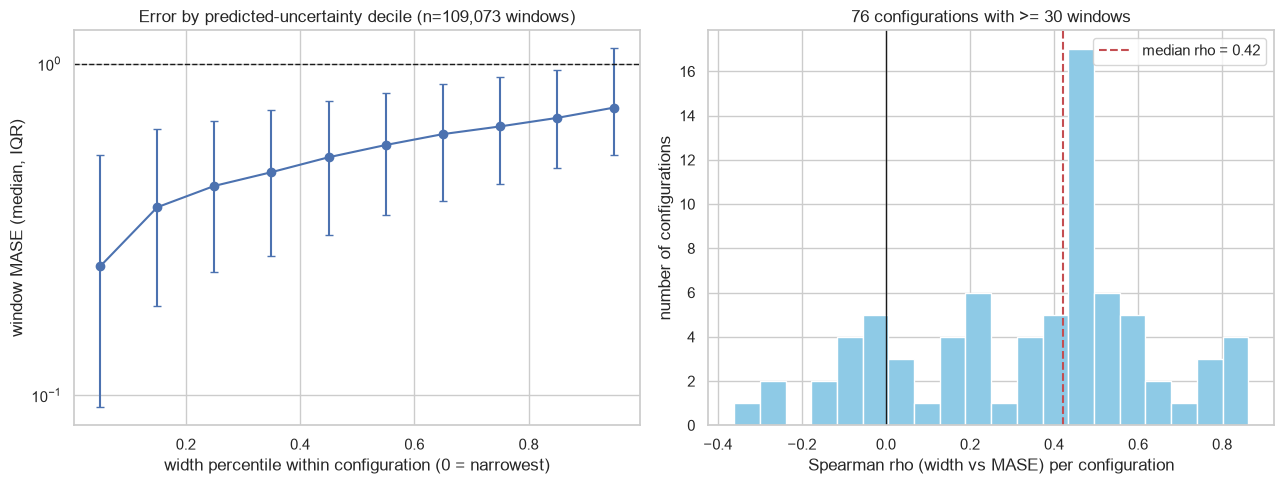

In [14]:
P.plot_width_vs_error(df_analysis)

Evaluating model self-awareness via predicted interval widths confirms interval width is informative about error. Across 109,073 windows, actual forecast error scales monotonically with predicted uncertainty deciles: windows in the narrowest 10th percentile achieve much lower MASE(~0.3), whereas windows in the widest 10th percentile yield MASE ~0.8. Wider confidence bounds directly correlate with higher actual error. 


Evaluating Spearman rank correlation ($\rho$) per configuration confirms that uncertainty calibration is structurally consistent, with a median correlation of $\rho = 0.42$ across 76 evaluated configurations. The sharp peak around $\rho \approx 0.45$ demonstrates that for most datasets, predicted interval widths reliably track actual error ranks. However, the minority of configurations exhibiting negative correlation ($\rho < 0$) pinpoint specific failure modes where sudden structural breaks cause overconfident prediction intervals

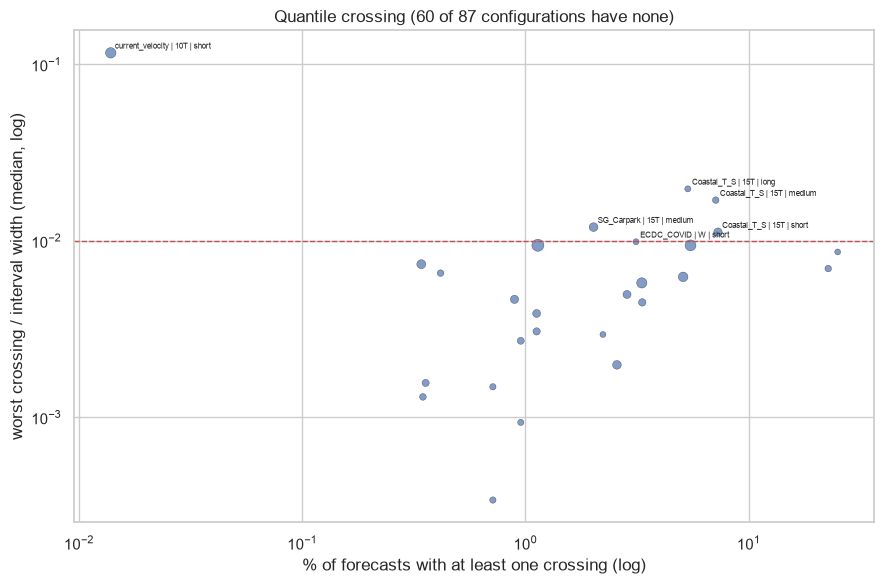

In [15]:
P.plot_crossing_overview(df_analysis)

Out of all 87 configurations, only 27 have quantile crossing. Of the 27, the vast majority is under the threshold for non-trivial violations (the red line). The configurations above belong mostly to a small subset of high-variance sensor series, Coastal_T_S dataset and current_velocity. Overall, the model has a good structural integrity.

## UMAP Visualisations

In [57]:
tbl_short = E.build_series_table(df_analysis, term="short")   # one row per series-variate
emb_short = E.embed(tbl_short, method="umap", n_neighbors=30, min_dist=0.1, max_per_dataset=500)
emb_short = E.cluster_embedding(emb_short, min_cluster_size=60)     # HDBSCAN on the 2-D map, -1 = noise

tbl_medium = E.build_series_table(df_analysis, term="medium")  
emb_medium = E.embed(tbl_medium, method="umap", n_neighbors=30, min_dist=0.1, max_per_dataset=500)
emb_medium = E.cluster_embedding(emb_medium, min_cluster_size=60)     

tbl_long = E.build_series_table(df_analysis, term="long")  
emb_long = E.embed(tbl_long, method="umap", n_neighbors=30, min_dist=0.1, max_per_dataset=500)
emb_long = E.cluster_embedding(emb_long, min_cluster_size=60)     

Rows dropped (missing features): {'SG_Carpark': 8, 'Crypto': 4}


C:\Users\steop\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
C:\Users\steop\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Rows dropped (missing features): {'SG_Carpark': 8}


C:\Users\steop\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
C:\Users\steop\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\steop\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest

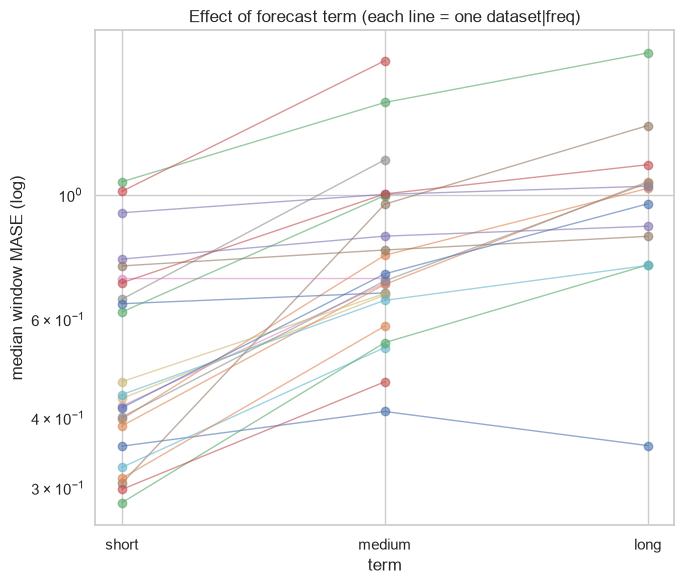

In [97]:
P.plot_term_comparison(df_config)

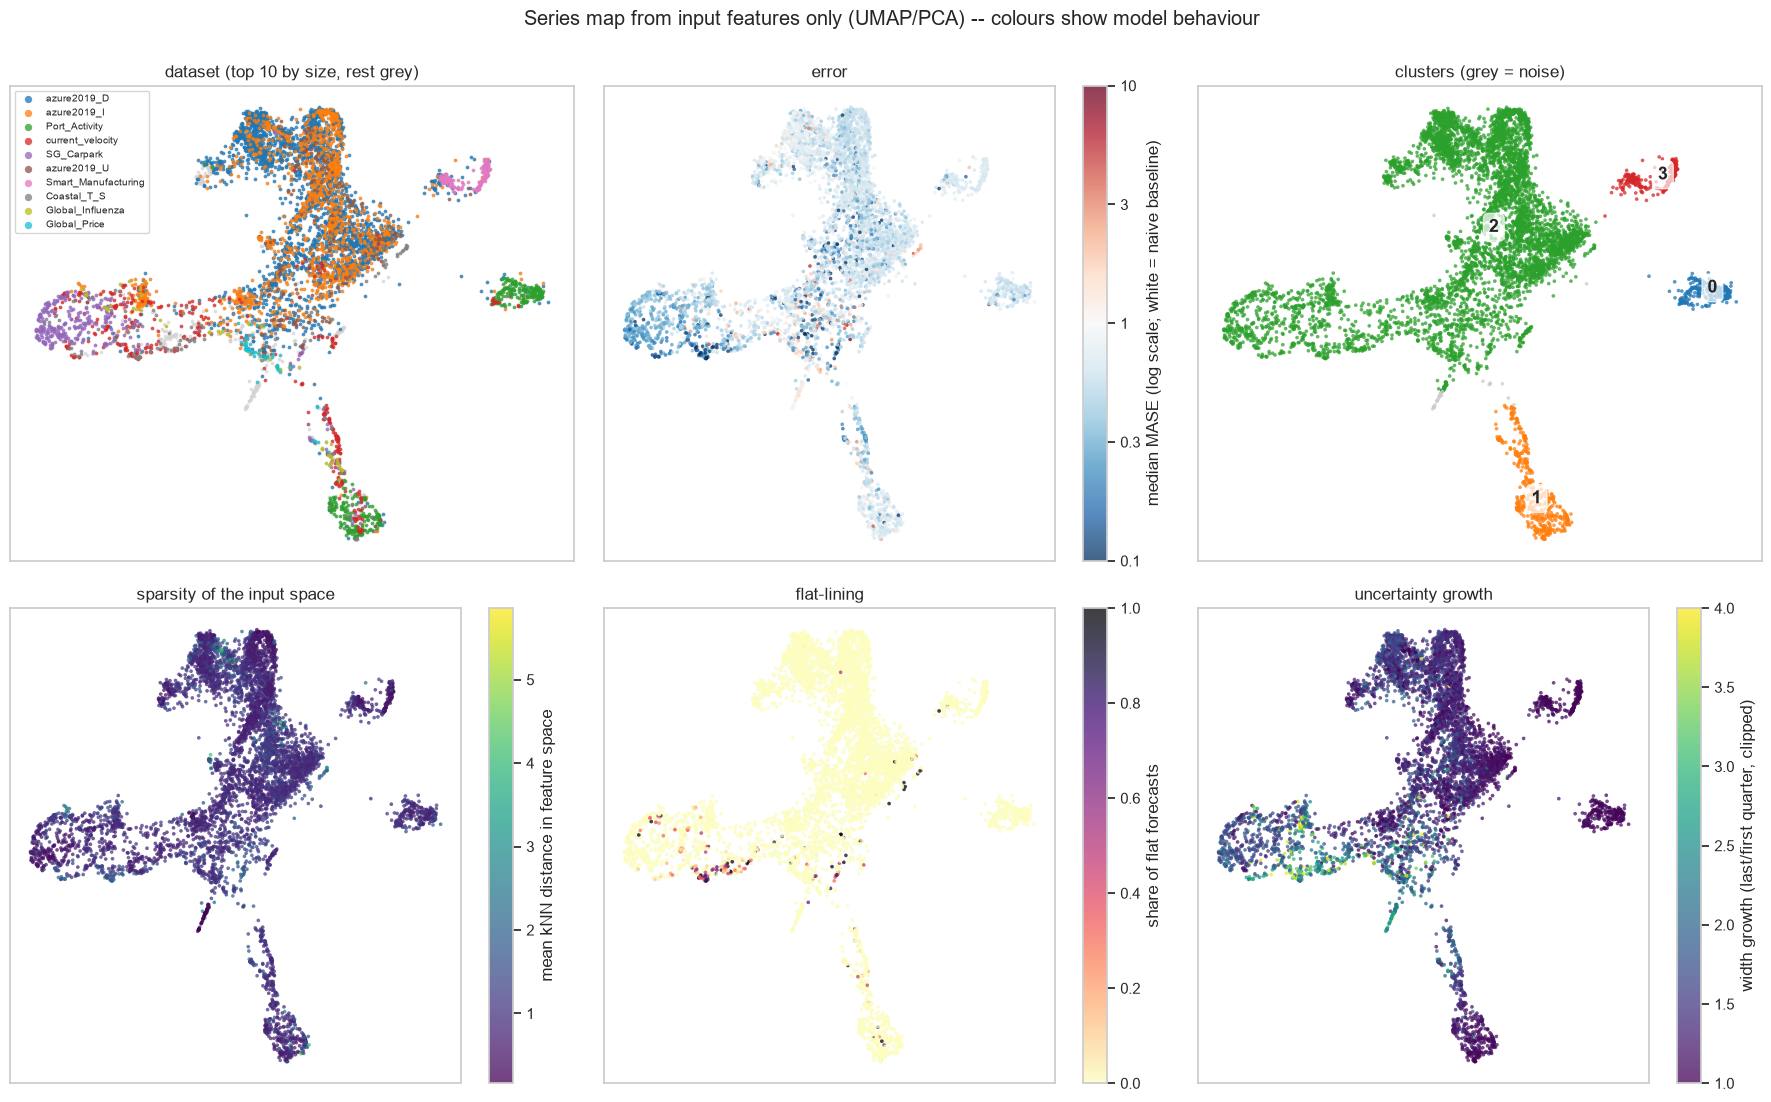

In [58]:
P.plot_embedding_panels(emb_short)                            

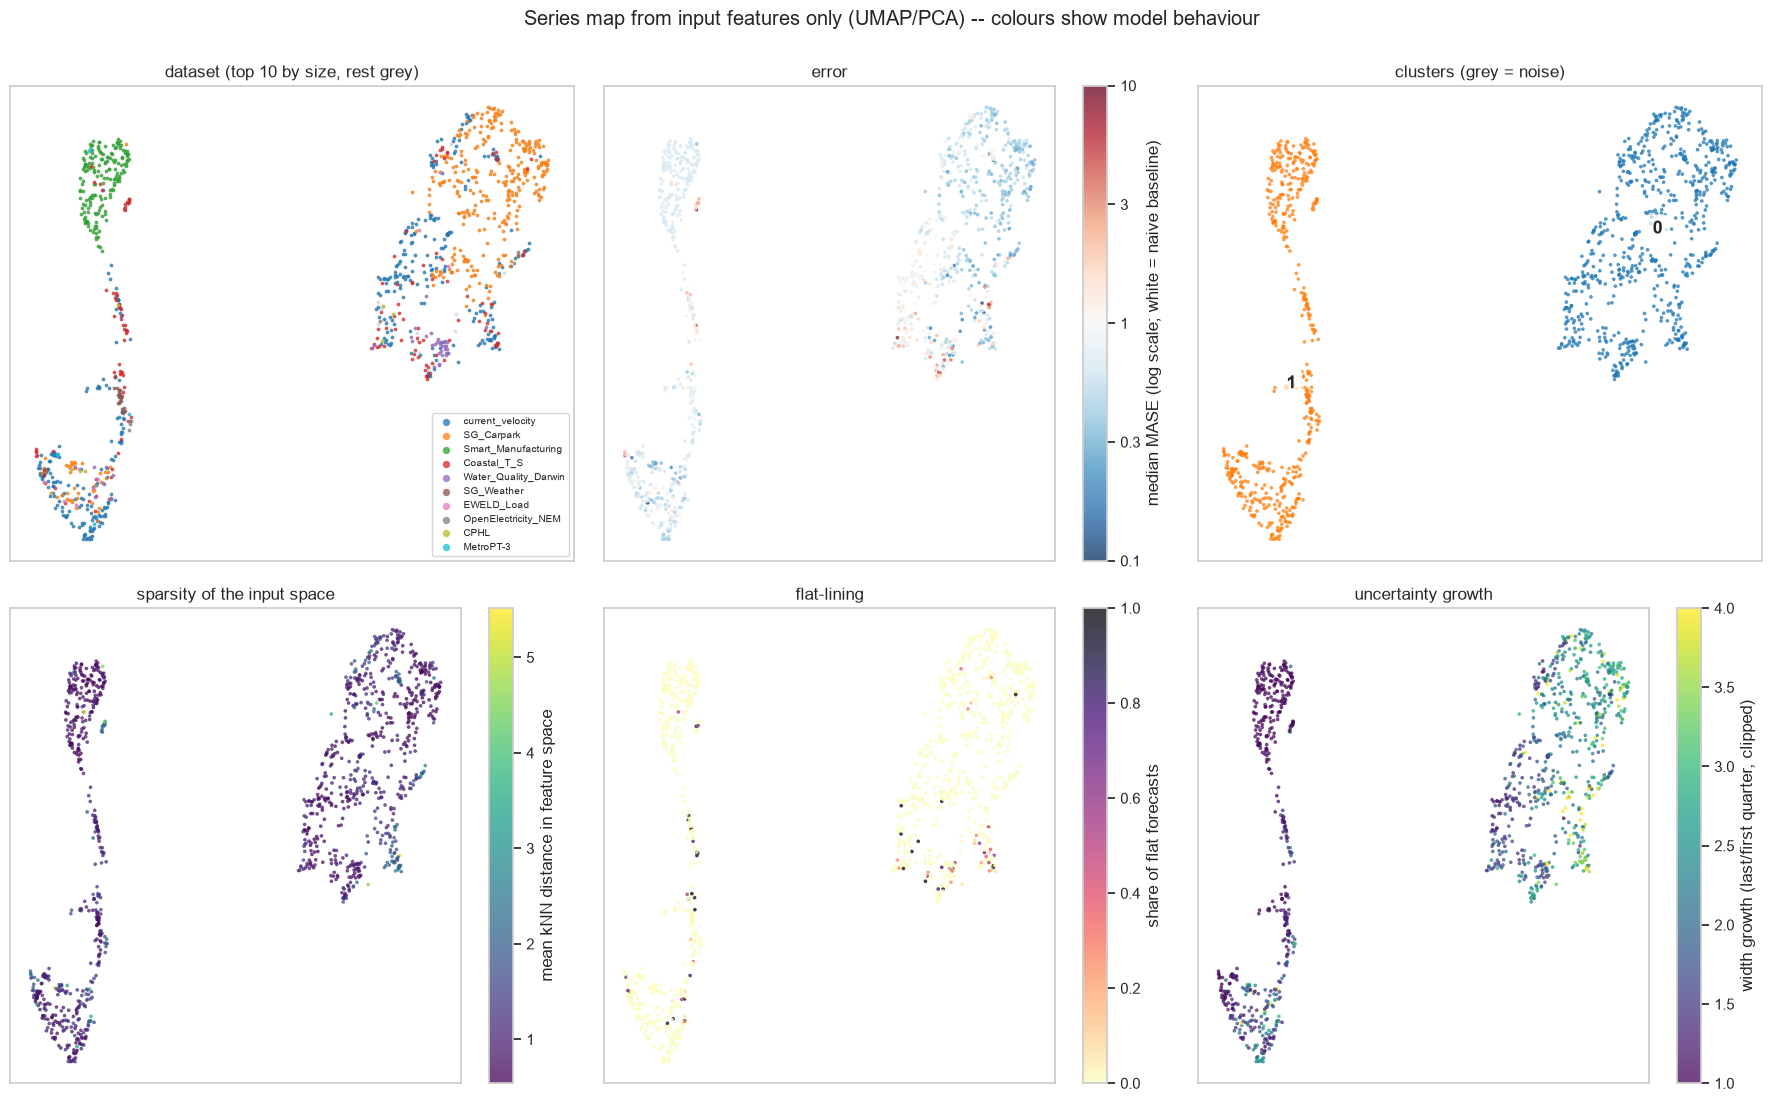

In [59]:
P.plot_embedding_panels(emb_medium)                            

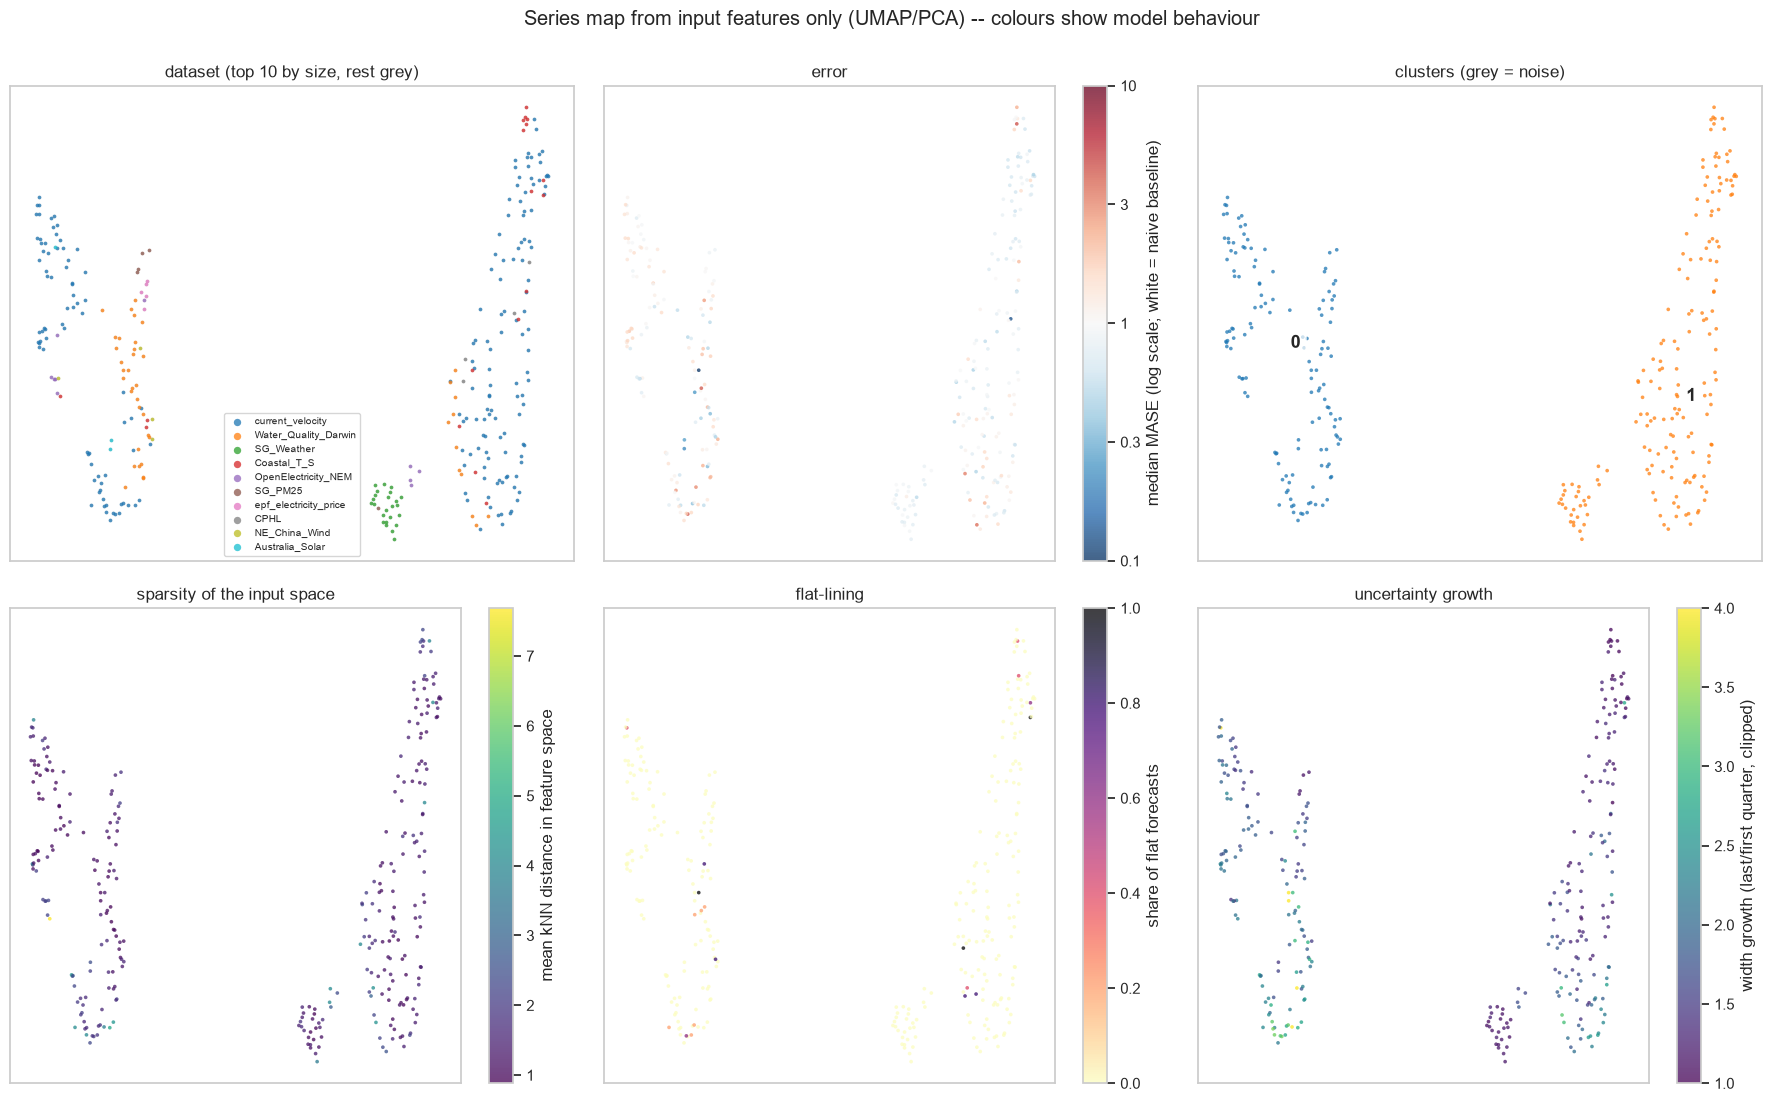

In [60]:
P.plot_embedding_panels(emb_long)                            

By projecting time series into a 2D-space using input features alone, we can evaluate how structural data proprieties change forecast behaviour across horizons. In short-term evaluation, the input space is split into a massive core surrounded by distint peripheral clusters. Cluster 2 forms the dominant core with 5688 series, achieving a stable median MASE of 0.65 alongide moderate uncertainty growth. Other clusters also achieve a median MASE of ~0.67. However, the noise group (Cluster -1) is exposing the model's primary short-term vulnerability:  with a median MASE of 1.10, failing to beat the naive baseline while exhibiting uncertainty growth. In the lower middle part of the left arm has the darkest blue points(MASE below 0.2), a streak of flat-lining and the highest width growth. The region coresponds mostly to current_velocity, Coastal_T_S. These 2 datasets are the same ones that topped the flat-lining. The error is pale blue almost everywhere. Cluster medians are nearly identical(0.65 for clusters 0, 1 , 2 and 0.7 for cluster 3). Clusters differ in spread, not typical error. These input features poorly separate typical median error across dense cluters, but strongly localize forecasting behaviours and isolate high-error outliers. It suggests that input features may not separate series according to their typical forecasting error, but may separate them according to how the model behaves when forecasting them

For the medium-term, the feature space contracts into two dominant clusters. Cluster 0, which is heavily represented by SG_Carpark, displays strong autocorrelation and seasonality, achieving a median MASE of 0.59. This cluster is also suffering from medium-term uncertainty growth, reaching 2.27. On the other hand, Cluster 1 has high entropy and negative autocorrelation, yielding a slightly higher median MASE of 0.72.

In the long-term horizon, the feature space is split again into two clusters, both of which are primarly drivenby current_velocity. Cluster 0 consists of highly periodic and persistent series, but achieves a median MASE of 1.08, despite its "good" features. On the other hand, Cluster 1 captures serios from the same dataset but different configurations and it is characterized by negative autocorrelation and higher entropy has a better long-term median MASE of 0.85 and more controlled uncertainty expansion.

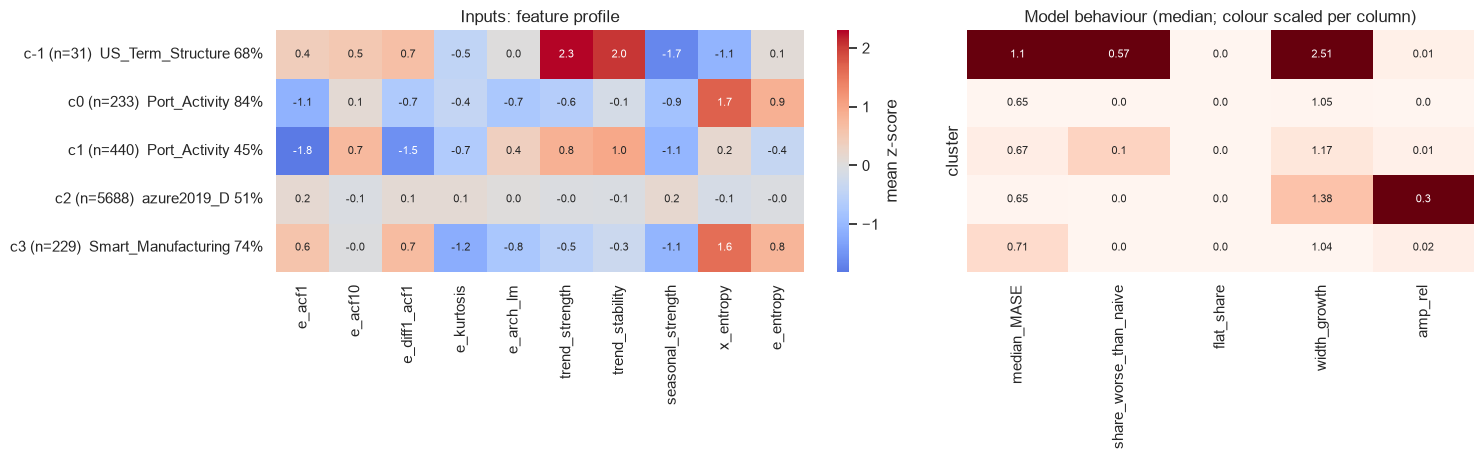

In [64]:
prof_short = E.cluster_profile(emb_short)                           # table: size, composition, feature z-scores, outcomes
P.plot_cluster_profile(prof_short)


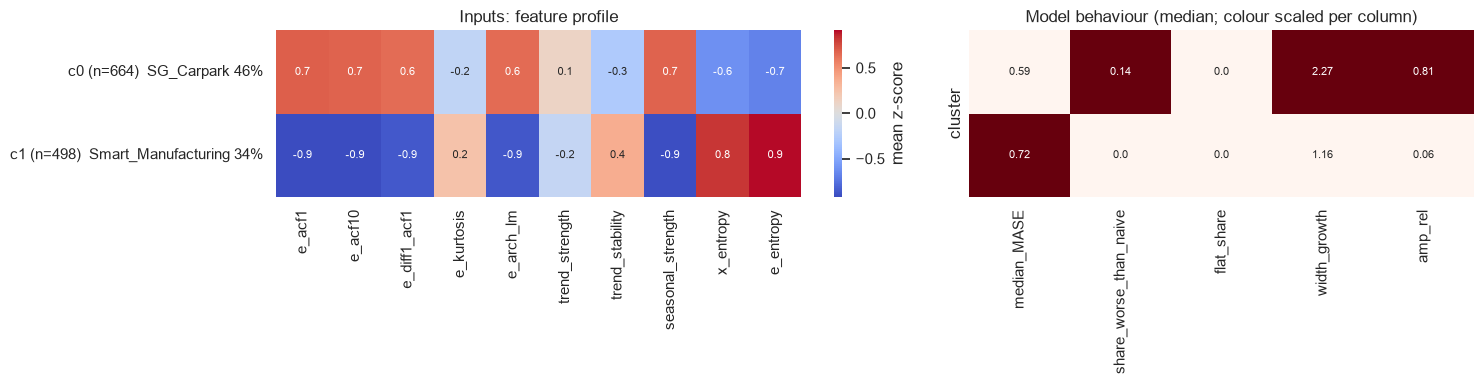

In [66]:
prof_medium = E.cluster_profile(emb_medium)                           
P.plot_cluster_profile(prof_medium)

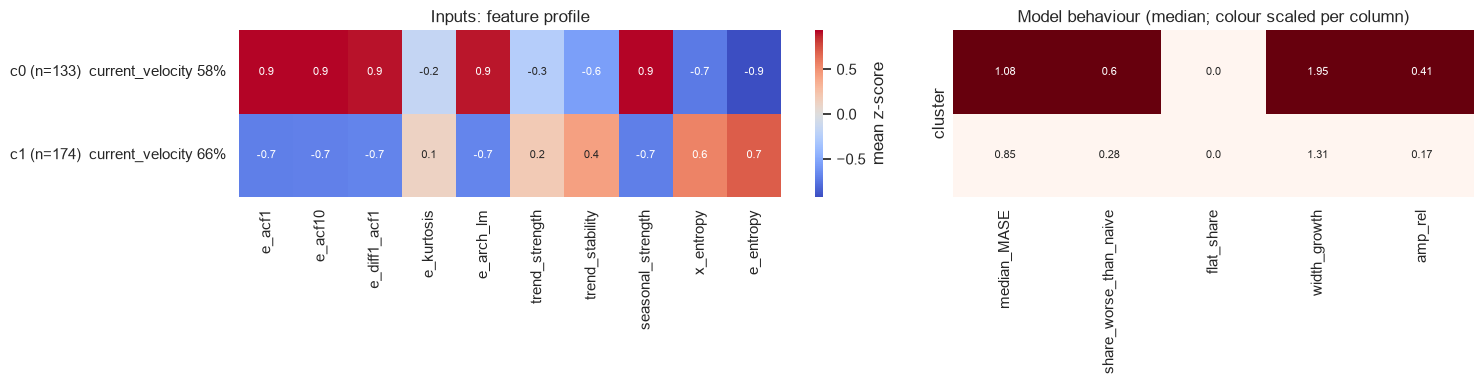

In [68]:
prof_long = E.cluster_profile(emb_long)                       
P.plot_cluster_profile(prof_long)

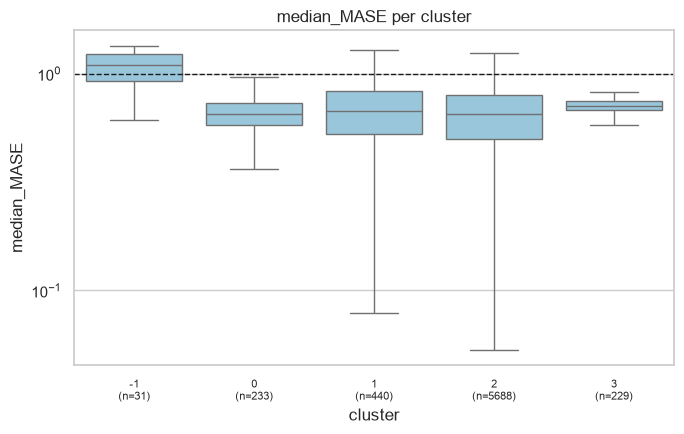

In [91]:
P.plot_cluster_distributions(emb_short, "median_MASE")

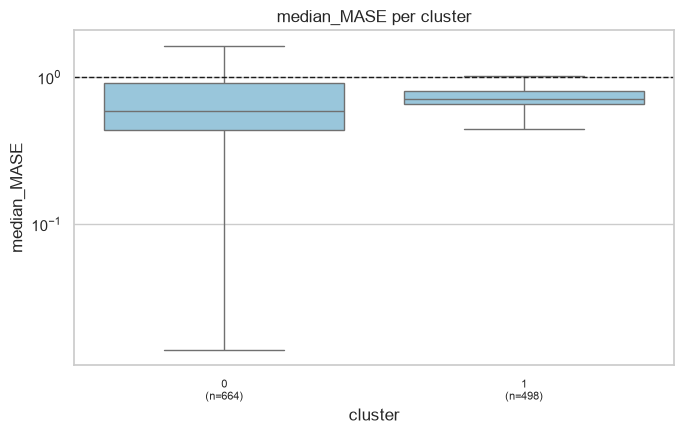

In [67]:
P.plot_cluster_distributions(emb_medium, "median_MASE")

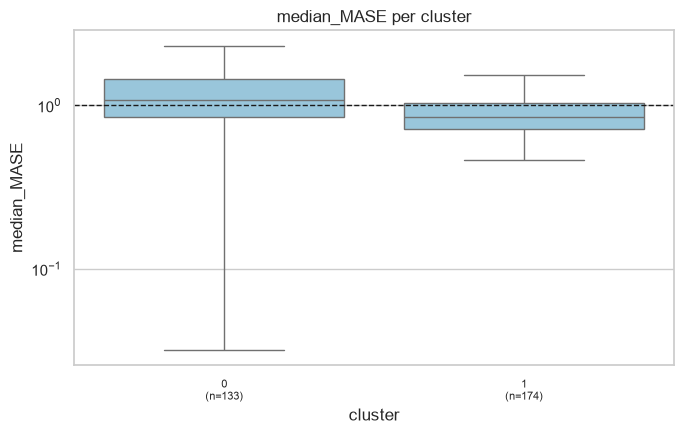

In [69]:
P.plot_cluster_distributions(emb_long, "median_MASE")

In [73]:
c = 0                                                   
dist = E.distinguishing_features(emb_long, c)                
P.plot_distinguishing(dist, c)

sub = E.subcluster(emb_long, c, method="umap", min_cluster_size=25)  
wb  = E.window_behavior_by_cluster(df_analysis, emb_long)   

wb

,n_windows,n_series,median_MASE,share_worse,flat_share,cross_share,width_growth,amp_rel,rho_width_vs_error
cluster,,,,,,,,,
0,14726,133,0.333486,0.087329,0.222260,0.000000,2.136364,0.110319,0.480316
1,20762,174,0.529692,0.171371,0.083604,0.007514,1.574122,0.052424,0.523400


In [81]:
c = 2                                                 
dist = E.distinguishing_features(emb_short, c)                
P.plot_distinguishing(dist, c)

sub = E.subcluster(emb_short, c, method="umap", min_cluster_size=25)  
wb  = E.window_behavior_by_cluster(df_analysis, emb_short)    

wb

,n_windows,n_series,median_MASE,share_worse,flat_share,cross_share,width_growth,amp_rel,rho_width_vs_error
cluster,,,,,,,,,
-1,1351,31,0.843720,0.372317,0.000740,0.000000,2.317722,0.024203,-0.044106
0,3627,233,0.660038,0.083264,0.000000,0.017645,1.058369,0.006903,0.287173
1,17966,440,0.531115,0.153846,0.060781,0.015084,1.427230,0.060402,0.422139
2,69829,5688,0.478754,0.138094,0.111508,0.014306,1.673851,0.153818,0.571786
3,2566,229,0.710404,0.027280,0.002338,0.003507,1.041962,0.014879,-0.046328


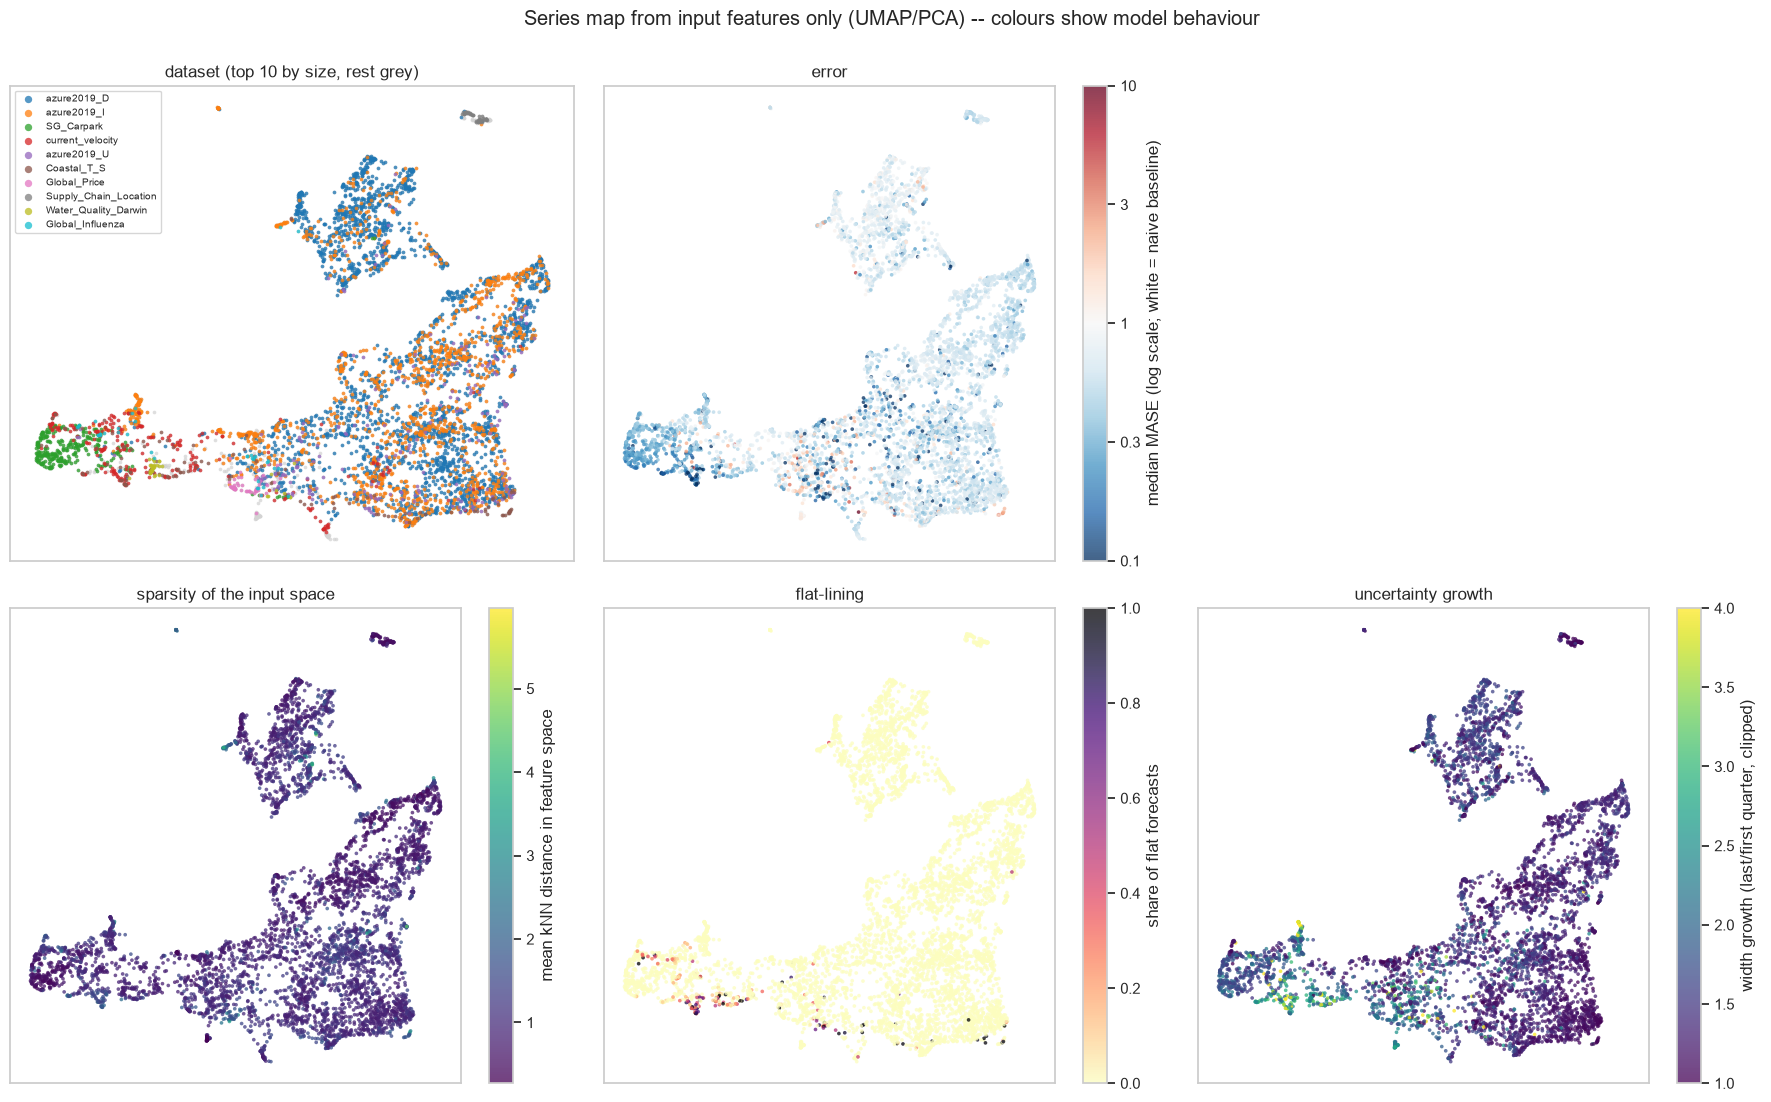

In [82]:
P.plot_embedding_panels(sub)

--- 1. Datasets in the Noise Cluster ---
dataset
US_Term_Structure    21
current_velocity      5
azure2019_D           4
Job_Claims            1
Name: count, dtype: int64

--- 3. Top Distinguishing Features for Noise Cluster ---


,variable,kind,AUC,cluster_median,rest_median,strength
0,trend_strength,feature,0.962940,0.994578,0.345924,0.462940
1,trend_stability,feature,0.955010,0.978083,0.136059,0.455010
2,seasonal_strength,feature,0.089784,0.147836,0.321742,0.410216
3,width_growth,outcome,0.877256,2.507825,1.343879,0.377256
4,share_worse_than_naive,outcome,0.851503,0.571429,0.000000,0.351503
5,amp_rel,outcome,0.155005,0.013158,0.254172,0.344995
6,x_entropy,feature,0.157932,0.345391,0.754909,0.342068
7,median_MASE,outcome,0.798840,1.098520,0.658866,0.298840
8,e_diff1_acf1,feature,0.721484,-0.194552,-0.466323,0.221484
9,e_acf10,feature,0.689114,0.323353,0.148140,0.189114


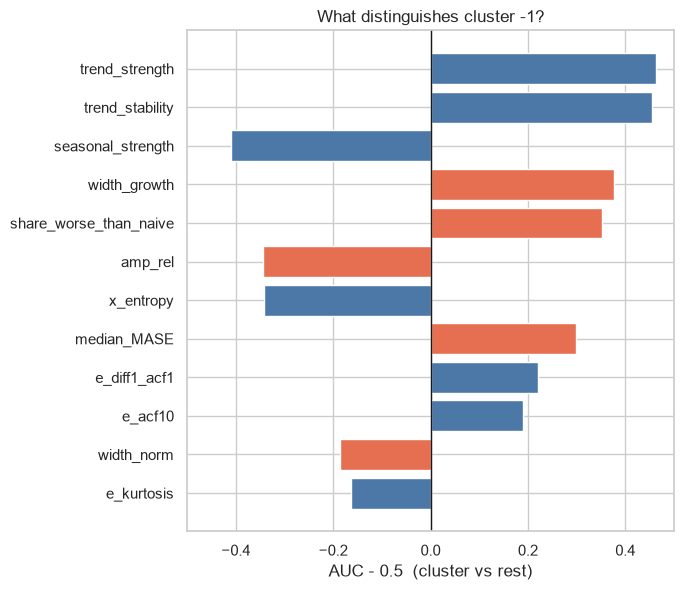


--- 4 & 5. Inspecting Individual Noise Series Forecast Fans ---


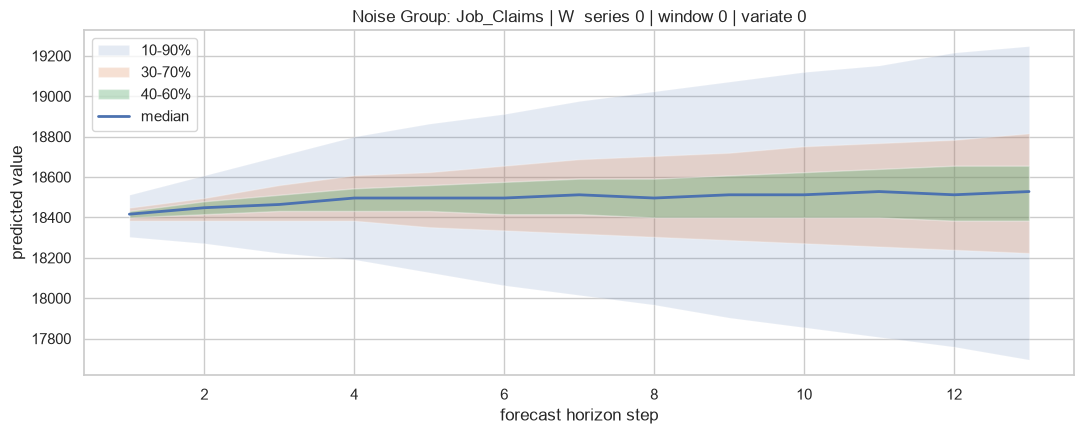

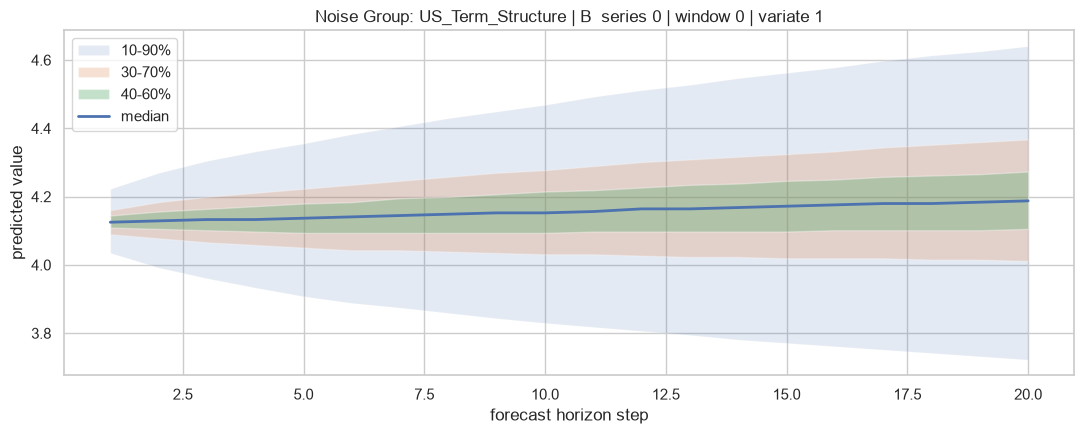

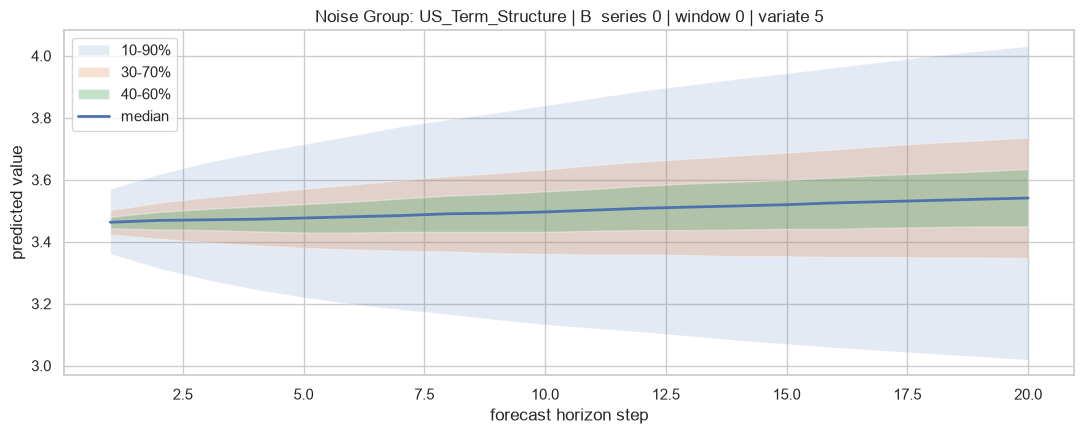

 Noise Group Behavior Summary (Medians)
median_MASE               1.098520
share_worse_than_naive    0.571429
flat_share                0.000000
width_growth              2.507825
dtype: float64


In [104]:
noise_series = emb_short[emb_short['cluster'] == -1]
print("--- 1. Datasets in the Noise Cluster ---")
print(noise_series['dataset'].value_counts())


dist_noise = E.distinguishing_features(emb_short, cluster=-1)
print("\n--- 3. Top Distinguishing Features for Noise Cluster ---")
display(dist_noise.head(10))

fig_dist = P.plot_distinguishing(dist_noise, cluster=-1)
display(fig_dist)


print("\n--- 4 & 5. Inspecting Individual Noise Series Forecast Fans ---")
RESULTS_DIR = "output/results/TiRex2"

sample_noise = noise_series.head(3)

for _, row in sample_noise.iterrows():
    ds = row['dataset']
    freq = str(row['freq'])
    s_idx = int(row['series_idx'])
    
    try:
        q, levels = d.load_config(RESULTS_DIR, ds, freq, term="short")
        
        fig_fan = P.plot_forecast_fan(
            q, levels, 
            series_idx=s_idx, 
            window_idx=0, 
            variate_idx=int(row['variate_idx']),
            title=f"Noise Group: {ds} | {freq}"
        )
        display(fig_fan)
    except Exception as e:
        print(f"Could not plot series {s_idx} for {ds} | {freq}: {e}")


noise_behavior = emb_short[emb_short['cluster'] == -1][
    ['median_MASE', 'share_worse_than_naive', 'flat_share', 'width_growth']
].median()

print(" Noise Group Behavior Summary (Medians)")
print(noise_behavior)

Although the UMAP feature space clusters most of the data into a central cluster, there is a small noisy cluster with a group of 31 series. After further investigation, we can see that the group doesnt consist of crazy, noisy data but rather a mix of economic/financial series. The noisy cluster actually has a high trend strength and trend stability, but the model fails due to the lack of repeating seasonal cycles. When examining the forecast trajectories, we can see why this group performs badly with a median MASE of 1.1.  Smooth, non-seasonal trend are more difficult for the model, the model's median forecast flat-lines or drifts sideways rather than following the historical trajectory. At the same time, the prediction intervals go into massive uncertainty bounds, reaching a median uncertinty growth of 2.51.

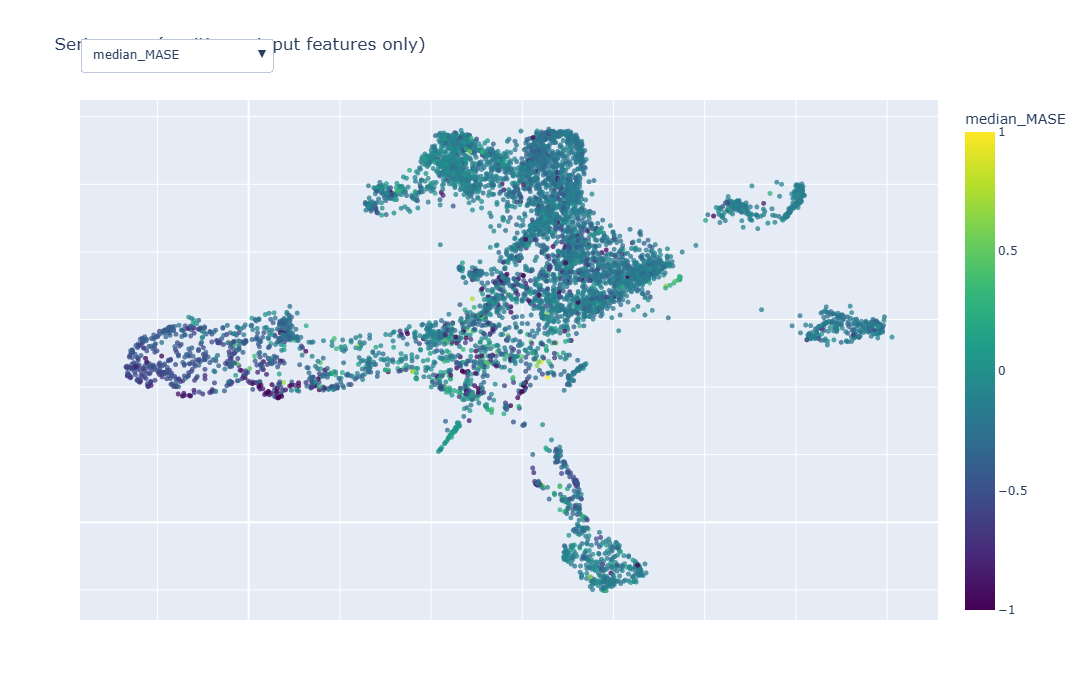

In [102]:
P.plot_embedding_interactive(emb_short)    # as the last line of a cell

In [95]:
# import ipywidgets as widgets
# from IPython.display import display, clear_output
# import plotly.graph_objects as go
# import numpy as np
# import pandas as pd

# # 1. Prepare data and sanitize NaNs for JSON compliance
# # Replace np.nan with None or drop them, depending on the column type.
# emb_safe = emb_all.copy()
# # Fill numeric NaNs with a safe fallback, or use Plotly's preferred method (None)
# emb_safe = emb_safe.replace({np.nan: None})

# configs = sorted((emb_safe['dataset'].astype(str) + " | " + 
#                   emb_safe['freq'].astype(str) + " | " + 
#                   emb_safe['term'].astype(str)).unique())

# # 2. Build the Dropdown UI
# dropdown_config = widgets.Dropdown(
#     options=['All Configurations'] + configs,
#     value='All Configurations',
#     description='Config:',
#     layout=widgets.Layout(width='400px')
# )

# # 3. Create a FigureWidget using the sanitized dataframe
# base_fig = P.plot_embedding_interactive(emb_safe)
# fig_widget = go.FigureWidget(base_fig)
# out_stats = widgets.Output()

# # 4. Define the update logic
# def update_dashboard(change):
#     selected = change['new']
    
#     with fig_widget.batch_update():
#         if selected == 'All Configurations':
#             fig_widget.data[0].marker.opacity = 0.75
#             fig_widget.data[0].marker.line.width = 0
#             fig_widget.layout.title.text = "Series map (position = input features only)"
#         else:
#             ds, fr, tm = selected.split(" | ")
#             mask = (emb_all['dataset'] == ds) & (emb_all['freq'] == fr) & (emb_all['term'] == tm)
            
#             # Apply mask to opacities
#             opacities = np.where(mask, 0.9, 0.05)
#             line_widths = np.where(mask, 1, 0)
            
#             fig_widget.data[0].marker.opacity = opacities
#             fig_widget.data[0].marker.line.width = line_widths
#             fig_widget.layout.title.text = f"Highlighted: {selected}"
            
#     with out_stats:
#         clear_output(wait=True)
#         if selected != 'All Configurations':
#             ds, fr, tm = selected.split(" | ")
#             mask = (emb_all['dataset'] == ds) & (emb_all['freq'] == fr) & (emb_all['term'] == tm)
#             subset = emb_all[mask]
            
#             if not subset.empty:
#                 dominant_cluster = subset['cluster'].mode()[0]
                
#                 print(f"--- Analysis for {selected} ---")
#                 print(f"Total Series: {len(subset)}")
#                 print(f"Dominant UMAP Cluster: {dominant_cluster}")
#                 print(f"Median MASE: {subset['median_MASE'].median():.3f}")
#                 print(f"Flat-lining Share: {subset['flat_share'].mean():.1%}")
                
#                 print(f"\n--- Distinguishing Features for Cluster {dominant_cluster} ---")
#                 dist = E.distinguishing_features(emb_all, dominant_cluster)
#                 display(dist.head(8))
#             else:
#                 print("No data available for this configuration.")

# # 5. Link and Display
# dropdown_config.observe(update_dashboard, names='value')
# display(widgets.VBox([dropdown_config, fig_widget, out_stats]))